# 03 · Fusion models

This notebook builds the **multi-modal** models, which use the PV history **and** the sky images together. Each section trains **one** model with 5-fold cross-validation; the last section lists the results. All models use the same history encoder (MLP) and the same folds, samples, training settings and metrics as the single-modality baselines in `02_baselines`. The image encoder is the CNN of `02_baselines` with two changes against overfitting (section 3.1), except in section 4.5, which uses a pre-trained encoder.

| Section | Models | Question |
|---|---|---|
| 4 | **Four fusion methods** (concatenation, residual, FiLM, cross-attention) and concatenation with a **pre-trained image encoder** | How should the images and the history be combined? |
| 5 | **Routing**: images to μ only; images to σ only | Do the images improve the forecast value, the uncertainty, or both? |
| 6 | **Control**: cross-attention trained on shuffled images | Is the gain due to the image content or only to the larger model? |
| 7 | **Results** | |

**Cross-attention is the main model**; routing and the control are built on it. The fusion methods and routing are run at all three horizons (15, 30, 60 minutes); the control at 15 minutes. The test set is not used in this notebook.


## 0 · Setup

Same paths, constants and training settings as in 02_baselines. The history part of every fusion model is the MLP encoder: in 02_baselines the three history architectures performed almost the same, and the MLP was the simplest and the best at 30 and 60 minutes.

In [31]:
import json, math, time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import stats, special
import torchvision

# paths
DATA_DIR = Path("data")
PROCESSED_DIR = DATA_DIR / "processed"
IMAGE_CACHE = PROCESSED_DIR / "images_rgb.npy"
EARLY_STOP_FILE = PROCESSED_DIR / "baselines" / "early_stop_days.json" # same early-stopping days as the baselines
RESULTS_DIR = PROCESSED_DIR / "fusion"
PRED_DIR = RESULTS_DIR / "predictions"     # out-of-fold predictions, one file per model and horizon
LOG_DIR = RESULTS_DIR / "train_logs"       # training log, one file per model and horizon
MODEL_DIR = RESULTS_DIR / "models"         # cross-attention fold models, for the attention maps (section 7.5)
for p in [PRED_DIR, LOG_DIR, MODEL_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# problem setup (identical to 02_baselines)
HORIZONS = [15, 30, 60]
HISTORY_MIN = 15
IMAGE_OFFSETS = [10, 5, 0]
N_FOLDS = 5
SEED = 1
WEATHER_BINS = ["clear", "variable", "overcast"]

# training settings (identical to 02_baselines)
TRAIN_CONFIG = dict(
    lr=1e-3, 
    weight_decay=1e-4, 
    batch_size=256,
    max_epochs=60, 
    early_stop_patience=10,
    lr_patience=3, 
    lr_min=1e-5,
    grad_clip=1.0,
)
RETRAIN = False                  # False: skip models whose predictions already exist

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

device: cuda NVIDIA GeForce RTX 4070 SUPER


## 1 · Data

The samples are loaded exactly as in `02_baselines` (section 1.1 there). The early-stopping days are read from the file saved by `02_baselines`, and the image cache built there is moved to the GPU, so both notebooks use identical data.

In [2]:
minutes = pd.read_csv(PROCESSED_DIR / "meta_processed.csv",
                      usecols=["split", "img_idx", "date", "pv_kw", "k", "p_clear", "sun_elev", "sun_azim"])
elev, azim = np.deg2rad(minutes["sun_elev"].to_numpy()), np.deg2rad(minutes["sun_azim"].to_numpy())
sun_per_minute = np.stack([np.sin(elev), np.sin(azim), np.cos(azim)], axis=1).astype(np.float32)

@dataclass
class HorizonData:
    horizon: int
    samples: pd.DataFrame          # row_t, row_y, fold, weather (kept for saving predictions)
    fold: np.ndarray
    weather: np.ndarray
    day: np.ndarray
    pv_history: np.ndarray         # (n, 15)
    k_history: np.ndarray          # (n, 15)
    sun: np.ndarray                # (n, 6) sun position at t and t+h
    image_rows: np.ndarray         # (n, 3) rows of the images at t-10, t-5, t
    pv_now: np.ndarray
    k_now: np.ndarray
    pv_target: np.ndarray
    k_target: np.ndarray
    clear_sky_target: np.ndarray

def load_horizon(h):
    s = pd.read_csv(PROCESSED_DIR / f"samples_h{h}.csv")
    s = s[s["fold"] >= 0].reset_index(drop=True)
    t, y = s["row_t"].to_numpy(), s["row_y"].to_numpy()
    history_rows = t[:, None] + np.arange(-HISTORY_MIN + 1, 1)
    pv, k = minutes["pv_kw"].to_numpy(np.float32), minutes["k"].to_numpy(np.float32)
    return HorizonData(
        horizon=h, samples=s[["row_t", "row_y", "fold", "weather"]],
        fold=s["fold"].to_numpy(), weather=s["weather"].to_numpy(), day=minutes["date"].to_numpy()[t],
        pv_history=pv[history_rows], k_history=k[history_rows],
        sun=np.concatenate([sun_per_minute[t], sun_per_minute[y]], axis=1),
        image_rows=t[:, None] - np.array(IMAGE_OFFSETS),
        pv_now=pv[t], k_now=k[t],
        pv_target=pv[y], k_target=k[y], clear_sky_target=minutes["p_clear"].to_numpy(np.float32)[y])

DATA = {h: load_horizon(h) for h in HORIZONS}
print(pd.DataFrame({f"{h} min": pd.Series(DATA[h].fold).value_counts().sort_index() for h in HORIZONS})
      .rename_axis("fold"))

# early-stopping days: the same as in 02_baselines
assert EARLY_STOP_FILE.exists(), "run 02_baselines first (it saves the early-stopping days)"
with open(EARLY_STOP_FILE) as fp:
    EARLY_STOP_DAYS = {int(fold): days for fold, days in json.load(fp).items()}

def split_masks(data, fold):
    in_train = data.fold != fold
    early_stop = in_train & np.isin(data.day, EARLY_STOP_DAYS[fold])
    return in_train & ~early_stop, early_stop, data.fold == fold       # fit, early stop, evaluate

# sky images on the GPU (row i = image of minute i)
assert IMAGE_CACHE.exists(), "run section 7.1 of 02_baselines first (it builds the image cache)"
IMAGES = torch.from_numpy(np.load(IMAGE_CACHE)).to(DEVICE)
print("image cache:", tuple(IMAGES.shape), f"{IMAGES.numel() / 1e9:.1f} GB on {DEVICE}")

      15 min  30 min  60 min
fold                        
0      59072   57402   54320
1      59464   57854   54791
2      59771   58114   54948
3      62175   60562   57383
4      60242   58590   55548
image cache: (331900, 3, 64, 64) 4.1 GB on cuda


## 2 · Shared tools

### 2.1 Forecast distribution and metrics

Identical to `02_baselines` (section 2.1): every model outputs a Student-t distribution (μ, σ, ν), and all metrics are computed in kW per fold and weather bin.

In [3]:
# CRPs function
def crps_student_t(z, nu):
    return (z * (2 * stats.t.cdf(z, nu) - 1)
            + 2 * stats.t.pdf(z, nu) * (nu + z ** 2) / (nu - 1)
            - 2 * np.sqrt(nu) * special.beta(0.5, nu - 0.5) / ((nu - 1) * special.beta(0.5, nu / 2) ** 2))

# compute metrics listed above: RMSE, MAE, coverage, width, NLL, CRPS, Winkler
def compute_metrics(y, mu, sigma, nu):
    error = y - mu
    z = error / sigma
    q = stats.t.ppf(0.95, nu)
    low, high = mu - q * sigma, mu + q * sigma
    return {
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAE": np.mean(np.abs(error)),
        "coverage": np.mean((y >= low) & (y <= high)),
        "width": np.mean(high - low),
        "NLL": np.mean(np.log(sigma) - stats.t.logpdf(z, nu)),
        "CRPS": np.mean(sigma * crps_student_t(z, nu)),
        "Winkler": np.mean((high - low) + (2 / 0.1) * ((low - y) * (y < low) + (y - high) * (y > high))),
    }

# return metrics for all folds and all weathers
def evaluate_predictions(pred):
    rows = []
    for fold in range(N_FOLDS):
        for weather in ["all"] + WEATHER_BINS:
            p = pred[(pred["fold"] == fold) & ((pred["weather"] == weather) | (weather == "all"))]
            m = compute_metrics(*(p[c].to_numpy() for c in ["y", "mu", "sigma", "nu"]))
            rows.append({"fold": fold, "weather": weather, "n": len(p), **m})
    return pd.DataFrame(rows)

def prediction_file(model, h):
    return PRED_DIR / f"{model}_h{h}.csv"

# save the result
def save_predictions(model, h, mu, sigma, nu):
    pred = DATA[h].samples.copy()
    pred["y"], pred["mu"], pred["sigma"], pred["nu"] = DATA[h].pv_target, mu, sigma, nu
    assert not pred[["mu", "sigma", "nu"]].isna().any().any()
    pred.to_csv(prediction_file(model, h), index=False)

### 2.2 Output head with routing, and training loop

The output head is the Student-t head of `02_baselines` (separate μ and σ heads, one learned ν), with one addition: it receives the **history features** and the **image features** separately, and `route` decides which head gets the image features:

- `"both"`: μ and σ both see the images (default);
- `"mu"`: only μ sees the images; σ is computed from the history alone;
- `"sigma"`: only σ sees the images; μ is computed from the history alone.

To keep this split clean, the μ and σ heads do not share a layer here. The training loop is the same as in `02_baselines` (Student-t NLL with an MSE warm-up epoch, AdamW, early stopping on the early-stopping days). `predict` can give each sample the images of **another** sample (`image_idx`), which is used for the shuffled-image test.

In [4]:
# all model output the same thing: student-t distrubution mean and sigma
class RoutedStudentTHead(nn.Module):
    def __init__(self, n_history, n_image, route="both", hidden=128, sigma_min=1e-3):
        super().__init__()
        assert route in ("both", "mu", "sigma")
        self.image_to_mu = route in ("both", "mu")
        self.image_to_sigma = route in ("both", "sigma")

        def branch(n_in):
            return nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden // 2), nn.ReLU(),
                                 nn.Linear(hidden // 2, 1))
        self.mu_head = branch(n_history + n_image * self.image_to_mu)
        self.sigma_head = branch(n_history + n_image * self.image_to_sigma)
        self.nu_raw = nn.Parameter(torch.tensor(1.0))
        self.sigma_min = sigma_min

    def forward(self, history_features, image_features):
        both = torch.cat([history_features, image_features], dim=1)
        mu = self.mu_head(both if self.image_to_mu else history_features).squeeze(-1)
        sigma_in = both if self.image_to_sigma else history_features
        sigma = F.softplus(self.sigma_head(sigma_in)).squeeze(-1) + self.sigma_min
        nu = 2 + F.softplus(self.nu_raw)
        return mu, sigma, nu

# define loss function as NLL
def student_t_nll(mu, sigma, nu, y):
    z = (y - mu) / sigma
    return (torch.lgamma(nu / 2) - torch.lgamma((nu + 1) / 2) + 0.5 * torch.log(nu * math.pi) + torch.log(sigma) + (nu + 1) / 2 * torch.log1p(z ** 2 / nu)).mean()

In [5]:
# forward pass
def forward_pass(model, batch):
    # mixed precision (bfloat16) for the image part; outputs back to float32 for the loss
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEVICE.type == "cuda"):
        mu, sigma, nu = model(batch)
    return mu.float(), sigma.float(), nu.float()

# predict function
@torch.no_grad()
def predict(model, get_batch, idx, image_idx=None, chunk=1024):
    # image_idx: optionally take the images of other samples (shuffled-image test)
    model.eval()
    mus, sigmas = [], []
    for i in range(0, len(idx), chunk):
        images_from = None if image_idx is None else image_idx[i:i + chunk]
        mu, sigma, nu = forward_pass(model, get_batch(idx[i:i + chunk], images_from))
        mus.append(mu)
        sigmas.append(sigma)
    return torch.cat(mus), torch.cat(sigmas), nu

# tranning function
def train_model(model, get_batch, target, fit_idx, stop_idx):
    cfg = TRAIN_CONFIG
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=cfg["lr_patience"], min_lr=cfg["lr_min"])
    best_nll, best_epoch, best_state, bad_epochs = np.inf, 0, None, 0

    for epoch in range(cfg["max_epochs"]):
        model.train()
        order = fit_idx[torch.randperm(len(fit_idx), device=DEVICE)]
        for i in range(0, len(order), cfg["batch_size"]):
            # forward
            idx = order[i:i + cfg["batch_size"]]
            mu, sigma, nu = forward_pass(model, get_batch(idx, train=True))

            # compute loss
            y = target[idx]
            loss = F.mse_loss(mu, y) if epoch == 0 else student_t_nll(mu, sigma, nu, y)

            # backward
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()

        mu, sigma, nu = predict(model, get_batch, stop_idx)
        stop_nll = student_t_nll(mu, sigma, nu, target[stop_idx]).item()
        if epoch == 0:
            continue
        sched.step(stop_nll)
        if stop_nll < best_nll:
            best_nll, best_epoch, bad_epochs = stop_nll, epoch, 0
            best_state = {n: v.detach().clone() for n, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= cfg["early_stop_patience"]:
                break

    model.load_state_dict(best_state)
    return dict(epochs=epoch + 1, best_epoch=best_epoch, early_stop_nll=round(best_nll, 4))

### 2.3 Inputs and cross-validation

`prepare_fusion` builds the inputs of one round: the clear-sky index history, the sun position and the sky images, standardised with the **fit** part of the round only (images are scaled to [0, 1]). The image input is the three frames at t−10, t−5 and t, stacked into 9 channels. The target is k at t+h, converted back to kW with the clear-sky power at t+h, as for the clear-sky index baselines.

The training images are changed a little at random in every batch (data augmentation, section 3.1); the early-stopping and evaluation images are never changed. With `shuffle_images=True`, every sample is given the images of another, randomly chosen sample (fixed permutation), so the images carry no information about the target (section 6).

`cross_validate` is the same as in `02_baselines`, with two additions:

1. if `shuffle_test=True`, the held-out fold is predicted a second time with the images shuffled among its samples (history and sun position unchanged). If the model really uses the image content, this should make the forecast clearly worse. These predictions are saved as `{name}_images_shuffled_at_test`;
2. if `save_model=True` (main cross-attention model only), the weights and the description of every fold model are saved to `models/`, for the attention maps in section 7.5. The test set is not predicted here: in `04_evaluation` the final models are retrained on the whole training set.

`run_fusion(name, model_class, horizons, ...)` trains one model at the given horizons and skips any horizon that is already done (unless `RETRAIN = True`).

In [6]:
def gpu(a, dtype=torch.float32):
    return torch.as_tensor(np.ascontiguousarray(a), dtype=dtype, device=DEVICE)

# image augmentation
def augment_frames(x):
    # x: (batch, 3 frames, 3, 64, 64) in [0, 1]; the same random change for the 3 frames of a sample,
    # so the movement of the clouds between the frames is kept
    b, dev = x.shape[0], x.device
    brightness = torch.empty(b, 1, 1, 1, 1, device=dev).uniform_(0.8, 1.2)
    contrast = torch.empty(b, 1, 1, 1, 1, device=dev).uniform_(0.8, 1.2)
    mean = x.mean(dim=(1, 2, 3, 4), keepdim=True)
    x = (x - mean) * contrast + mean * brightness + 0.02 * torch.randn_like(x)
    # shift of up to 2 pixels (no rotation or flip: they would move the sun away from its true position)
    theta = torch.zeros(b, 2, 3, device=dev)
    theta[:, 0, 0] = 1
    theta[:, 1, 1] = 1
    theta[:, :, 2] = torch.empty(b, 2, device=dev).uniform_(-2 / 32, 2 / 32)
    flat = x.flatten(1, 2)
    grid = F.affine_grid(theta, list(flat.shape), align_corners=False)
    flat = F.grid_sample(flat, grid, padding_mode="zeros", align_corners=False)
    return flat.view_as(x).clamp(0, 1)

# images of a batch: the 3 frames stacked into 9 channels, augmented for training batches
def make_images(frames, augment=False):
    # frames: (batch, 3 frames, 3, 64, 64) uint8, in the order t-10, t-5, t
    x = frames.float().div_(255)
    if augment:
        x = augment_frames(x)
    return x.flatten(1, 2)                                # (batch, 9, 64, 64)

def prepare_fusion(data, fit, shuffle_images=False):
    history, target, to_kw = data.k_history, data.k_target, data.clear_sky_target
    norm = dict(history_mean=history[fit].mean(), history_std=history[fit].std(),
                sun_mean=data.sun[fit].mean(0), sun_std=data.sun[fit].std(0) + 1e-6,
                y_mean=target[fit].mean(), y_std=target[fit].std())
    history_z = gpu((history - norm["history_mean"]) / norm["history_std"])
    sun_z = gpu((data.sun - norm["sun_mean"]) / norm["sun_std"])

    image_rows = data.image_rows
    if shuffle_images:                                   # images no longer belong to their sample
        image_rows = image_rows[np.random.default_rng(SEED).permutation(len(image_rows))]
    image_rows = gpu(image_rows, torch.long)

    def get_batch(idx, images_from=None, train=False):
        frames = IMAGES[image_rows[idx if images_from is None else images_from]]
        return {"history": history_z[idx], "sun": sun_z[idx],
                "images": make_images(frames, augment=train)}   # augment training batches only

    target_z = gpu((target - norm["y_mean"]) / norm["y_std"])
    return get_batch, target_z, norm, to_kw

# 5-fold cross validation
def cross_validate(name, h, build_model, description, shuffle_images=False, shuffle_test=False, save_model=False):
    data = DATA[h]
    n = len(data.fold)
    pred = {key: np.full(n, np.nan) for key in ["mu", "sigma", "nu", "mu_shuf", "sigma_shuf"]}
    log = []
    for fold in range(N_FOLDS):
        start = time.time()
        fit, early_stop, evaluate = split_masks(data, fold)
        get_batch, target, norm, to_kw = prepare_fusion(data, fit, shuffle_images)

        torch.manual_seed(SEED * 100 + fold)
        model = build_model().to(DEVICE)
        info = train_model(model, get_batch, target, gpu(np.flatnonzero(fit), torch.long), gpu(np.flatnonzero(early_stop), torch.long))
        if save_model:                                    # for the attention maps (section 7.5)
            torch.save({"state_dict": model.state_dict(), "description": description}, MODEL_DIR / f"{name}_h{h}_fold{fold}.pt")

        eval_idx = gpu(np.flatnonzero(evaluate), torch.long)
        outputs = {"": predict(model, get_batch, eval_idx)}
        if shuffle_test:                                  # same samples, images of other samples
            perm = torch.as_tensor(np.random.default_rng(SEED + fold).permutation(len(eval_idx)), device=DEVICE)
            outputs["_shuf"] = predict(model, get_batch, eval_idx, image_idx=eval_idx[perm])
        for suffix, (mu, sigma, nu) in outputs.items():
            pred["mu" + suffix][evaluate] = (mu.cpu().numpy() * norm["y_std"] + norm["y_mean"]) * to_kw[evaluate]
            pred["sigma" + suffix][evaluate] = sigma.cpu().numpy() * norm["y_std"] * to_kw[evaluate]
        pred["nu"][evaluate] = outputs[""][2].item()

        info.update(model=name, horizon=h, fold=fold, nu=round(outputs[""][2].item(), 3),
                    n_params=sum(p.numel() for p in model.parameters()), minutes=round((time.time() - start) / 60, 2))
        log.append(info)
        print(f"  fold {fold}: {info['epochs']} epochs (best {info['best_epoch']}), "
              f"early-stop NLL {info['early_stop_nll']:.3f}, nu {info['nu']:.2f}, {info['minutes']:.1f} min")

    save_predictions(name, h, pred["mu"], pred["sigma"], pred["nu"])
    if shuffle_test:
        save_predictions(f"{name}_images_shuffled_at_test", h, pred["mu_shuf"], pred["sigma_shuf"], pred["nu"])
    pd.DataFrame(log).to_csv(LOG_DIR / f"{name}_h{h}.csv", index=False)

def run_fusion(name, model_class, horizons, model_kwargs=None, shuffle_images=False, shuffle_test=False, save_model=False):
    kwargs = model_kwargs or {}
    description = dict(model_class=model_class.__name__, model_kwargs=kwargs, shuffle_images=shuffle_images)
    for h in horizons:
        if prediction_file(name, h).exists() and not RETRAIN:
            print(f"{name}, h={h}: already done, skipped")
            continue
        print(f"{name}, h={h}:")
        cross_validate(name, h, lambda: model_class(**kwargs), description, shuffle_images, shuffle_test, save_model)

## 3 · Building blocks

### 3.1 History and image encoders (from `02_baselines`)

The encoders are copied unchanged from `02_baselines`, so the fusion models contain exactly the same history and image parts as the baselines:

- **history encoder:** an MLP over the 15 values of k (two layers of 128);
- **image encoder:** the residual CNN over the stacked frames, with the 9 channels of the three stacked frames as input, giving a 128 × 8 × 8 feature map.

**Changes to the image encoder against overfitting.** In `02_baselines`, the image-only CNN reached its best early-stopping score after only 1–6 epochs in every fold and then got steadily worse on unseen days: it overfits quickly. A likely reason is that the several hundred images of one day are very similar, so the network can memorise individual days instead of learning how clouds affect the output. Since every fusion model except the one in section 4.5 contains this encoder, two standard measures are added here; the image part differs from the CNN baseline in this respect only:

1. **Data augmentation**: in every training batch the images are changed a little at random, the same way for the three frames of a sample, so the cloud movement between the frames is kept: brightness and contrast × 0.8–1.2, small noise (std 0.02), and a shift of up to 2 pixels. Rotations and flips are **not** used, because they would move the sun away from its true position, which the model also receives as an input. Early-stopping and evaluation images are never changed.
2. **Spatial dropout** (10%) after each block of the CNN: during training, 10% of the feature channels are switched off at random, so the network cannot rely on a few specific features to recognise a particular day.

In [27]:
class MLPEncoder(nn.Module):
    def __init__(self, seq_len=HISTORY_MIN, hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(seq_len, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.out_dim = hidden

    def forward(self, history):
        return self.net(history)

class ResidualBlock(nn.Module):
    def __init__(self, c_in, c_out):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.skip = nn.Identity() if c_in == c_out else nn.Sequential(nn.Conv2d(c_in, c_out, 1, bias=False), nn.BatchNorm2d(c_out))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        return F.relu(self.bn2(self.conv2(out)) + self.skip(x))

class ImageEncoder(nn.Module):
    def __init__(self, in_channels=9, widths=(32, 64, 128), dropout=0.1):
        super().__init__()
        layers = [nn.Conv2d(in_channels, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU()]
        c = widths[0]
        for w in widths:
            layers += [ResidualBlock(c, w), nn.MaxPool2d(2), nn.Dropout2d(dropout)]   # spatial dropout
            c = w
        self.net = nn.Sequential(*layers)
        self.out_channels = c

    def forward(self, images):
        return self.net(images)                          # (batch, 128, 8, 8)

### 3.2 The fusion methods

Concatenation and residual fusion are the two designs studied by the Stanford group (SUNSET and Venugopal et al. 2019); cross-attention is our main model. In these three, the CNN looks at the images without knowing the history, and the two inputs meet only after the image features are extracted; a fourth design combines them **earlier**, inside the CNN (FiLM). All four use the same history encoder and the same CNN image encoder; they differ only in **how** the two inputs meet. "History features" below means the history encoder output joined with the sun position.

| Method | How the inputs are combined |
|---|---|
| **Concatenation** | the image feature map is pooled to 4 × 4 regions and summarised in 128 features (a **global** view of the sky), which are joined with the history features, as in SUNSET |
| **Residual** | a forecast is made from the history alone, and the images then **correct** it: μ = μ_history + Δμ, σ = σ_history · exp(Δ). The best design among the 28 studied by Venugopal et al. (2019) |
| **FiLM (early fusion)** | the history features scale and shift every channel of the CNN feature maps after each block (feature-wise linear modulation, Perez et al. 2018), so the CNN already knows the history while it looks at the images; then as concatenation |
| **Cross-attention** | the global view of concatenation **plus** a **local** view: 4 queries look at the 64 regions (8 × 8) of the image feature map, and each takes a weighted average of the regions relevant to it |

```
cross-attention (main model):

history (15 × k) ─► history encoder ─┐
sun position (6) ────────────────────┴─► history features ─► query 1 ─┐
                                                learned queries 2–4 ───┤
                                                                       ▼
sky images (9 × 64 × 64) ─► CNN ─► 8 × 8 map ─┬─► 64 tokens ─► cross-attention ─► local features (128)
                                               └─► 4 × 4 pooling ─────────────────► global features (128)
                                                                                          │
              history features + global features + local features ─► Student-t head (μ, σ, ν)
```

The attention block is multi-head cross-attention (4 heads, 128 dims) followed by a small feed-forward layer, both with residual connections and layer normalisation. Query 1 is computed from the history features, so it can depend on the current situation; queries 2–4 are learned. Routing (section 5) is applied to the cross-attention model. The global view gives the model the whole sky, which matters more at longer horizons; the local view lets it focus on the regions most relevant to the forecast, such as the clouds near the sun.

In [32]:
def mlp_branch(n_in, n_out=1, hidden=128):
    return nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden // 2), nn.ReLU(),
                         nn.Linear(hidden // 2, n_out))

def image_summary(channels, dropout):
    # global view, same summary of the CNN feature map as the image baseline: pool to 4 x 4, flatten, linear 128
    return nn.Sequential(nn.AdaptiveAvgPool2d(4), nn.Flatten(), nn.Linear(channels * 16, 128), nn.ReLU(),
                         nn.Dropout(dropout))

class ConcatFusion(nn.Module):
    # pooled image features joined with the history features (SUNSET-style)
    def __init__(self, route="both", dropout=0.3):
        super().__init__()
        self.history_encoder = MLPEncoder()
        self.image_encoder = ImageEncoder()
        self.summary = image_summary(self.image_encoder.out_channels, dropout)
        self.head = RoutedStudentTHead(self.history_encoder.out_dim + 6, 128, route)

    def forward(self, batch):
        history_features = torch.cat([self.history_encoder(batch["history"]), batch["sun"]], dim=1).float()
        image_features = self.summary(self.image_encoder(batch["images"])).float()
        return self.head(history_features, image_features)

class CrossAttentionBlock(nn.Module):
    # the queries attend to the image tokens, then a feed-forward layer; residual connections around both
    def __init__(self, d_model, heads, dropout):
        super().__init__()
        self.norm_query = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(d_model, heads, dropout=dropout, batch_first=True)
        self.feed_forward = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, 2 * d_model), nn.GELU(),
                                          nn.Dropout(dropout), nn.Linear(2 * d_model, d_model))

    def forward(self, query, tokens, keep_attention=False):
        attended, weights = self.attention(self.norm_query(query), tokens, tokens, need_weights=keep_attention)
        query = query + attended
        return query + self.feed_forward(query), weights

class CrossAttentionFusion(nn.Module):
    # global view (pooled summary, as in concatenation) + local view (4 queries over the 64 image regions)
    def __init__(self, route="both", n_queries=4, d_model=128, heads=4, dropout=0.3):
        super().__init__()
        self.history_encoder = MLPEncoder()
        self.image_encoder = ImageEncoder()
        n_history = self.history_encoder.out_dim + 6
        self.summary = image_summary(self.image_encoder.out_channels, dropout)              # global view (128)
        self.history_query = nn.Linear(n_history, d_model)                                   # query 1: from the history
        self.learned_queries = nn.Parameter(torch.randn(1, n_queries - 1, d_model) * 0.02)   # queries 2..n: learned
        self.token_proj = nn.Linear(self.image_encoder.out_channels, d_model)
        self.token_position = nn.Parameter(torch.randn(1, 64, d_model) * 0.02)             # one per 8 x 8 region
        self.norm_tokens = nn.LayerNorm(d_model)
        self.attention = CrossAttentionBlock(d_model, heads, dropout=0.1)
        self.local = nn.Sequential(nn.Flatten(), nn.Linear(n_queries * d_model, 128), nn.ReLU(),
                                   nn.Dropout(dropout))                                     # local view (128)
        self.head = RoutedStudentTHead(n_history, 256, route)
        self.keep_attention = False                       # True: store the attention weights (for plots)
        self.last_attention = None

    def forward(self, batch):
        history_features = torch.cat([self.history_encoder(batch["history"]), batch["sun"]], dim=1).float()
        feature_map = self.image_encoder(batch["images"])                         # (batch, 128, 8, 8)
        tokens = self.token_proj(feature_map.flatten(2).transpose(1, 2)) + self.token_position
        tokens = self.norm_tokens(tokens)                                         # (batch, 64, d)
        queries = torch.cat([self.history_query(history_features).unsqueeze(1),
                             self.learned_queries.expand(len(tokens), -1, -1)], dim=1)   # (batch, 4, d)
        queries, weights = self.attention(queries, tokens, self.keep_attention)
        if self.keep_attention:
            self.last_attention = weights.reshape(len(tokens), -1, 8, 8).float()  # (batch, 4, 8, 8), mean over heads
        image_features = torch.cat([self.summary(feature_map), self.local(queries)], dim=1).float()
        return self.head(history_features, image_features)

class ResidualFusion(nn.Module):
    # two-step: forecast from the history, then the images correct mu and/or sigma
    def __init__(self, route="both", dropout=0.3, sigma_min=1e-3):
        super().__init__()
        self.history_encoder = MLPEncoder()
        self.image_encoder = ImageEncoder()
        self.summary = image_summary(self.image_encoder.out_channels, dropout)
        n_history = self.history_encoder.out_dim + 6
        self.history_forecast = mlp_branch(n_history, 2)          # mu, sigma from the history alone
        self.correction = mlp_branch(n_history + 128, 2)          # corrections from images + history
        nn.init.zeros_(self.correction[-1].weight)                # start with no correction
        nn.init.zeros_(self.correction[-1].bias)
        self.correct_mu = route in ("both", "mu")
        self.correct_sigma = route in ("both", "sigma")
        self.nu_raw = nn.Parameter(torch.tensor(1.0))
        self.sigma_min = sigma_min

    def forward(self, batch):
        history_features = torch.cat([self.history_encoder(batch["history"]), batch["sun"]], dim=1).float()
        image_features = self.summary(self.image_encoder(batch["images"])).float()
        base = self.history_forecast(history_features)
        delta = self.correction(torch.cat([history_features, image_features], dim=1))
        mu = base[:, 0] + (delta[:, 0] if self.correct_mu else 0)
        log_factor = delta[:, 1].clamp(-5, 5) if self.correct_sigma else 0
        sigma = (F.softplus(base[:, 1]) + self.sigma_min) * torch.exp(log_factor)
        return mu, sigma, 2 + F.softplus(self.nu_raw)


class FiLMFusion(nn.Module):
    # early fusion: the history features scale and shift the CNN feature maps after every block (FiLM)
    def __init__(self, route="both", dropout=0.3):
        super().__init__()
        self.history_encoder = MLPEncoder()
        n_history = self.history_encoder.out_dim + 6
        encoder = ImageEncoder()
        layers = list(encoder.net)                       # stem (conv, norm, relu), then 3 x (block, pool, dropout)
        self.stem = nn.Sequential(*layers[:3])
        self.blocks = nn.ModuleList(nn.Sequential(*layers[i:i + 3]) for i in (3, 6, 9))
        self.film = nn.ModuleList(nn.Linear(n_history, 2 * w) for w in (32, 64, 128))   # scale and shift per channel
        for f in self.film:                              # start with no modulation (= concatenation)
            nn.init.zeros_(f.weight)
            nn.init.zeros_(f.bias)
        self.summary = image_summary(encoder.out_channels, dropout)
        self.head = RoutedStudentTHead(n_history, 128, route)

    def forward(self, batch):
        history_features = torch.cat([self.history_encoder(batch["history"]), batch["sun"]], dim=1).float()
        x = self.stem(batch["images"])
        for block, film in zip(self.blocks, self.film):
            x = block(x)
            scale, shift = film(history_features).to(x.dtype)[:, :, None, None].chunk(2, dim=1)
            x = x * (1 + scale) + shift
        return self.head(history_features, self.summary(x).float())


class PretrainedConcatFusion(nn.Module):
    # concatenation with a frozen ImageNet pre-trained ResNet-18 instead of the CNN trained from scratch
    def __init__(self, route="both", dropout=0.3):
        super().__init__()
        self.history_encoder = MLPEncoder()
        n_history = self.history_encoder.out_dim + 6
        resnet = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        self.backbone = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool,
                                      resnet.layer1, resnet.layer2, resnet.layer3)      # (frame, 256, 4, 4) for 64 x 64
        self.backbone.requires_grad_(False)                                             # frozen
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))   # ImageNet normalisation
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.reduce = nn.Sequential(nn.Conv2d(3 * 256, 128, 1), nn.ReLU())               # 3 frames -> 128 channels
        self.summary = image_summary(128, dropout)                                        # as concatenation
        self.head = RoutedStudentTHead(n_history, 128, route)

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()                     # frozen: batch-norm statistics stay those of ImageNet
        return self

    def forward(self, batch):
        history_features = torch.cat([self.history_encoder(batch["history"]), batch["sun"]], dim=1).float()
        frames = batch["images"].unflatten(1, (3, 3))                                     # (batch, 3 frames, 3, 64, 64)
        with torch.no_grad():
            x = self.backbone((frames.flatten(0, 1) - self.mean) / self.std)            # (batch * 3, 256, 4, 4)
        x = x.unflatten(0, (len(frames), 3)).flatten(1, 2)                               # (batch, 768, 4, 4)
        return self.head(history_features, self.summary(self.reduce(x)).float())


## 4 · Fusion methods

Each model in this section is trained with 5-fold cross-validation at all three horizons. After every round the held-out fold is also predicted with the images **shuffled among its samples** (history and sun position unchanged): if the forecast gets clearly worse, the method really uses the image content.


In [19]:
METHOD_HORIZONS = HORIZONS     # section 4: fusion methods
ROUTING_HORIZONS = HORIZONS    # section 5: routing
CONTROL_HORIZONS = [15]        # section 6: shuffled images in training

### 4.1 Concatenation (SUNSET-style)

The pooled image features are joined with the history features and passed to the Student-t head.

In [10]:
run_fusion("fusion_concat", ConcatFusion, METHOD_HORIZONS, shuffle_test=True)

fusion_concat, h=15: already done, skipped
fusion_concat, h=30: already done, skipped
fusion_concat, h=60: already done, skipped


### 4.2 Residual (two-step) fusion

A history-only forecast is corrected by the images. The correction layer starts at zero, so training begins from the history forecast.

In [11]:
run_fusion("fusion_residual", ResidualFusion, METHOD_HORIZONS, shuffle_test=True)

fusion_residual, h=15: already done, skipped
fusion_residual, h=30: already done, skipped
fusion_residual, h=60: already done, skipped


### 4.3 FiLM (early fusion)

The history features scale and shift the CNN feature maps after each block, so the CNN already knows the history while it looks at the images. The modulation starts at zero, so training begins from the concatenation model.


In [33]:
run_fusion("fusion_film", FiLMFusion, METHOD_HORIZONS, shuffle_test=True)

fusion_film, h=15:
  fold 0: 20 epochs (best 9), early-stop NLL -0.809, nu 3.39, 10.6 min
  fold 1: 19 epochs (best 8), early-stop NLL -0.771, nu 3.23, 10.1 min
  fold 2: 23 epochs (best 12), early-stop NLL -0.637, nu 3.53, 12.0 min
  fold 3: 22 epochs (best 11), early-stop NLL -1.026, nu 3.44, 11.4 min
  fold 4: 19 epochs (best 8), early-stop NLL -0.913, nu 3.39, 9.9 min
fusion_film, h=30:
  fold 0: 17 epochs (best 6), early-stop NLL -0.538, nu 3.05, 8.7 min
  fold 1: 22 epochs (best 11), early-stop NLL -0.460, nu 3.10, 11.2 min
  fold 2: 15 epochs (best 4), early-stop NLL -0.377, nu 3.00, 7.7 min
  fold 3: 16 epochs (best 5), early-stop NLL -0.744, nu 2.97, 8.1 min
  fold 4: 20 epochs (best 9), early-stop NLL -0.661, nu 3.22, 10.2 min
fusion_film, h=60:
  fold 0: 15 epochs (best 4), early-stop NLL -0.250, nu 2.76, 7.2 min
  fold 1: 15 epochs (best 4), early-stop NLL -0.170, nu 2.76, 7.3 min
  fold 2: 18 epochs (best 7), early-stop NLL -0.132, nu 2.81, 8.7 min
  fold 3: 15 epochs (bes

### 4.4 Cross-attention (main model)

The global view and the four queries over the 64 image regions (section 3.2) go to the Student-t head together with the history features. The fold models are saved for the attention maps (section 7.5).

In [12]:
run_fusion("fusion_xattn", CrossAttentionFusion, METHOD_HORIZONS, shuffle_test=True, save_model=True)

fusion_xattn, h=15:
  fold 0: 23 epochs (best 12), early-stop NLL -0.820, nu 3.39, 12.7 min
  fold 1: 29 epochs (best 18), early-stop NLL -0.785, nu 3.43, 15.8 min
  fold 2: 34 epochs (best 23), early-stop NLL -0.642, nu 3.71, 19.8 min
  fold 3: 31 epochs (best 20), early-stop NLL -1.058, nu 3.71, 19.6 min
  fold 4: 31 epochs (best 20), early-stop NLL -0.953, nu 3.66, 18.6 min
fusion_xattn, h=30:
  fold 0: 23 epochs (best 12), early-stop NLL -0.554, nu 3.23, 12.4 min
  fold 1: 21 epochs (best 10), early-stop NLL -0.496, nu 2.98, 11.1 min
  fold 2: 24 epochs (best 13), early-stop NLL -0.393, nu 3.25, 12.7 min
  fold 3: 20 epochs (best 9), early-stop NLL -0.774, nu 3.05, 10.5 min
  fold 4: 23 epochs (best 12), early-stop NLL -0.693, nu 3.23, 14.3 min
fusion_xattn, h=60:
  fold 0: 15 epochs (best 4), early-stop NLL -0.255, nu 2.75, 9.1 min
  fold 1: 17 epochs (best 6), early-stop NLL -0.215, nu 2.65, 10.3 min
  fold 2: 14 epochs (best 3), early-stop NLL -0.123, nu 2.81, 8.5 min
  fold 3: 

### 4.5 Concatenation with a pre-trained image encoder

The CNN trained from scratch overfits quickly (section 3.1). Here the image encoder of concatenation is replaced by a ResNet-18 pre-trained on ImageNet (up to its third block: 256 × 4 × 4 features per frame), which is kept **frozen**: each frame is passed through it separately, the features of the three frames are joined and reduced to 128 channels, and the rest is as in concatenation. A frozen encoder cannot overfit to individual days and needs no learning rate of its own. This tests whether general image features learned from a large dataset help, following Nie et al. (2024), who found that pre-training on more data improves sky-image forecasting.


In [34]:
run_fusion("fusion_pretrained", PretrainedConcatFusion, METHOD_HORIZONS, shuffle_test=True)

fusion_pretrained, h=15:
  fold 0: 18 epochs (best 7), early-stop NLL -0.771, nu 3.12, 3.3 min
  fold 1: 17 epochs (best 6), early-stop NLL -0.733, nu 3.08, 3.1 min
  fold 2: 17 epochs (best 6), early-stop NLL -0.618, nu 3.14, 3.1 min
  fold 3: 24 epochs (best 13), early-stop NLL -1.008, nu 3.38, 4.3 min
  fold 4: 20 epochs (best 9), early-stop NLL -0.916, nu 3.29, 3.6 min
fusion_pretrained, h=30:
  fold 0: 12 epochs (best 1), early-stop NLL -0.542, nu 3.13, 2.1 min
  fold 1: 12 epochs (best 1), early-stop NLL -0.436, nu 3.11, 2.1 min
  fold 2: 16 epochs (best 5), early-stop NLL -0.341, nu 3.00, 2.8 min
  fold 3: 14 epochs (best 3), early-stop NLL -0.683, nu 2.99, 2.5 min
  fold 4: 19 epochs (best 8), early-stop NLL -0.637, nu 3.03, 3.3 min
fusion_pretrained, h=60:
  fold 0: 13 epochs (best 2), early-stop NLL -0.164, nu 2.90, 2.2 min
  fold 1: 13 epochs (best 2), early-stop NLL -0.127, nu 2.88, 2.2 min
  fold 2: 13 epochs (best 2), early-stop NLL -0.089, nu 2.91, 2.2 min
  fold 3: 12 e

## 5 · Routing: do the images help μ, σ, or both?

The main cross-attention model sends the image features to both heads. Here they go **only to μ** or **only to σ** (section 2.2). Compared with section 4.4, this shows whether the images mainly improve the forecast value (accuracy) or the uncertainty (reliability). Run at all three horizons (`ROUTING_HORIZONS`).

### 5.1 Images to μ only

In [20]:
run_fusion("fusion_xattn_images_to_mu", CrossAttentionFusion, ROUTING_HORIZONS, model_kwargs=dict(route="mu"))

fusion_xattn_images_to_mu, h=15: already done, skipped
fusion_xattn_images_to_mu, h=30:
  fold 0: 30 epochs (best 19), early-stop NLL -0.498, nu 2.13, 17.0 min
  fold 1: 27 epochs (best 16), early-stop NLL -0.444, nu 2.10, 14.2 min
  fold 2: 22 epochs (best 11), early-stop NLL -0.295, nu 2.19, 11.5 min
  fold 3: 21 epochs (best 10), early-stop NLL -0.695, nu 2.22, 10.9 min
  fold 4: 26 epochs (best 15), early-stop NLL -0.625, nu 2.16, 13.6 min
fusion_xattn_images_to_mu, h=60:
  fold 0: 19 epochs (best 8), early-stop NLL -0.183, nu 2.17, 9.5 min
  fold 1: 21 epochs (best 10), early-stop NLL -0.153, nu 2.11, 10.9 min
  fold 2: 18 epochs (best 7), early-stop NLL 0.009, nu 2.22, 9.1 min
  fold 3: 24 epochs (best 13), early-stop NLL -0.410, nu 2.12, 11.9 min
  fold 4: 16 epochs (best 5), early-stop NLL -0.325, nu 2.30, 8.1 min


### 5.2 Images to σ only

In [21]:
run_fusion("fusion_xattn_images_to_sigma", CrossAttentionFusion, ROUTING_HORIZONS, model_kwargs=dict(route="sigma"))

fusion_xattn_images_to_sigma, h=15: already done, skipped
fusion_xattn_images_to_sigma, h=30:
  fold 0: 25 epochs (best 14), early-stop NLL -0.522, nu 3.48, 14.1 min
  fold 1: 18 epochs (best 7), early-stop NLL -0.453, nu 3.04, 9.6 min
  fold 2: 25 epochs (best 14), early-stop NLL -0.334, nu 3.58, 13.2 min
  fold 3: 33 epochs (best 22), early-stop NLL -0.691, nu 3.97, 17.0 min
  fold 4: 22 epochs (best 11), early-stop NLL -0.639, nu 3.38, 11.4 min
fusion_xattn_images_to_sigma, h=60:
  fold 0: 17 epochs (best 6), early-stop NLL -0.215, nu 2.83, 8.5 min
  fold 1: 18 epochs (best 7), early-stop NLL -0.158, nu 2.81, 9.1 min
  fold 2: 24 epochs (best 13), early-stop NLL -0.054, nu 3.27, 13.6 min
  fold 3: 18 epochs (best 7), early-stop NLL -0.403, nu 2.86, 9.7 min
  fold 4: 14 epochs (best 3), early-stop NLL -0.346, nu 2.84, 7.1 min


## 6 · Control: training with shuffled images

A fusion model has more parameters than the history model, so a gain could in principle come from the larger model alone. Here the cross-attention model is trained with **shuffled images**: every sample gets the images of another, randomly chosen sample (fixed permutation), so the images carry no information about the target, while the model and the training stay the same, at 15 minutes (`CONTROL_HORIZONS`). If this model is no better than the history-only model, any gain of the real model comes from the image content.

In [15]:
run_fusion("fusion_xattn_images_shuffled_in_training", CrossAttentionFusion, CONTROL_HORIZONS, shuffle_images=True)

fusion_xattn_images_shuffled_in_training, h=15:
  fold 0: 37 epochs (best 26), early-stop NLL -0.732, nu 2.44, 20.6 min
  fold 1: 29 epochs (best 18), early-stop NLL -0.716, nu 2.39, 16.5 min
  fold 2: 33 epochs (best 22), early-stop NLL -0.552, nu 2.48, 18.7 min
  fold 3: 31 epochs (best 20), early-stop NLL -0.974, nu 2.47, 17.3 min
  fold 4: 38 epochs (best 27), early-stop NLL -0.870, nu 2.51, 21.5 min


## 7 · Results

Metrics are recomputed from the saved out-of-fold predictions, in kW. They describe the fusion models only; the comparison with the single-modality baselines, after conformal calibration, is made in `04_evaluation`.

### 7.1 Fusion methods

Mean ± std over the 5 folds, all weather.

In [35]:
METRICS = ["RMSE", "CRPS", "NLL", "coverage", "width"]
METHODS = {"fusion_concat": "Concatenation", "fusion_residual": "Residual (two-step)", "fusion_film": "FiLM (early fusion)",
           "fusion_xattn": "Cross-attention", "fusion_pretrained": "Concatenation, pre-trained encoder"}

def fold_metrics(model, h):
    r = evaluate_predictions(pd.read_csv(prediction_file(model, h)))
    r.insert(0, "model", model)
    r.insert(1, "horizon", h)
    return r

def mean_std(r):
    g = r.groupby("model", sort=False)[METRICS]
    return g.mean().map("{:.3f}".format) + " ± " + g.std().map("{:.3f}".format)

results = pd.concat([fold_metrics(m, h) for m in METHODS for h in HORIZONS], ignore_index=True)
for h in HORIZONS:
    print(f"\n{h} minutes")
    display(mean_std(results[(results["horizon"] == h) & (results["weather"] == "all")]).rename(index=METHODS))


15 minutes


,RMSE,CRPS,NLL,coverage,width
model,,,,,
Concatenation,1.932 ± 0.088,0.545 ± 0.046,0.292 ± 0.111,0.888 ± 0.020,2.931 ± 0.153
Residual (two-step),1.958 ± 0.104,0.553 ± 0.048,0.302 ± 0.114,0.885 ± 0.025,2.839 ± 0.219
FiLM (early fusion),1.968 ± 0.089,0.552 ± 0.044,0.305 ± 0.115,0.883 ± 0.019,2.932 ± 0.291
Cross-attention,1.946 ± 0.093,0.546 ± 0.043,0.284 ± 0.107,0.886 ± 0.011,2.890 ± 0.269
"Concatenation, pre-trained encoder",2.013 ± 0.127,0.571 ± 0.053,0.347 ± 0.117,0.875 ± 0.007,2.914 ± 0.310



30 minutes


,RMSE,CRPS,NLL,coverage,width
model,,,,,
Concatenation,2.182 ± 0.102,0.660 ± 0.055,0.593 ± 0.112,0.886 ± 0.021,3.564 ± 0.345
Residual (two-step),2.204 ± 0.083,0.666 ± 0.050,0.597 ± 0.105,0.882 ± 0.026,3.516 ± 0.455
FiLM (early fusion),2.220 ± 0.090,0.672 ± 0.054,0.617 ± 0.100,0.886 ± 0.025,3.605 ± 0.369
Cross-attention,2.191 ± 0.089,0.660 ± 0.047,0.583 ± 0.106,0.881 ± 0.005,3.495 ± 0.320
"Concatenation, pre-trained encoder",2.265 ± 0.136,0.686 ± 0.059,0.644 ± 0.087,0.888 ± 0.015,3.733 ± 0.229



60 minutes


,RMSE,CRPS,NLL,coverage,width
model,,,,,
Concatenation,2.495 ± 0.149,0.805 ± 0.069,0.906 ± 0.118,0.881 ± 0.017,4.319 ± 0.539
Residual (two-step),2.510 ± 0.117,0.814 ± 0.067,0.920 ± 0.119,0.887 ± 0.029,4.775 ± 0.445
FiLM (early fusion),2.580 ± 0.148,0.832 ± 0.076,0.935 ± 0.106,0.885 ± 0.021,4.323 ± 0.384
Cross-attention,2.492 ± 0.127,0.806 ± 0.067,0.918 ± 0.119,0.886 ± 0.008,4.547 ± 0.351
"Concatenation, pre-trained encoder",2.584 ± 0.107,0.838 ± 0.063,0.972 ± 0.109,0.876 ± 0.027,4.115 ± 0.336


### 7.2 By weather

CRPS (kW, mean over the 5 folds) in each weather bin.

In [36]:
crps = results.groupby(["model", "horizon", "weather"], sort=False)["CRPS"].mean().unstack(["horizon", "weather"])
display(crps.reindex(columns=["all"] + WEATHER_BINS, level=1).rename(index=METHODS).round(3))

horizon                                15                              30  \
weather                               all  clear variable overcast    all   
model                                                                       
Concatenation                       0.545  0.148    1.459    1.281  0.660   
Residual (two-step)                 0.553  0.148    1.480    1.325  0.666   
FiLM (early fusion)                 0.552  0.150    1.483    1.290  0.672   
Cross-attention                     0.546  0.148    1.462    1.294  0.660   
Concatenation, pre-trained encoder  0.571  0.154    1.528    1.356  0.686   

horizon                                                         60         \
weather                             clear variable overcast    all  clear   
model                                                                       
Concatenation                       0.205    1.615    1.794  0.805  0.282   
Residual (two-step)                 0.205    1.644    1.794  0.814  0.289   
FiLM (early fusion)                 0.211    1.648    1.809  0.832  0.288   
Cross-attention                     0.204    1.619    1.805  0.806  0.284   
Concatenation, pre-trained encoder  0.213    1.683    1.854  0.838  0.290   

horizon                                               
weather                            variable overcast  
model                                                 
Concatenation                         1.780    2.473  
Residual (two-step)                   1.799    2.476  
FiLM (early fusion)                   1.832    2.617  
Cross-attention                       1.776    2.483  
Concatenation, pre-trained encoder    1.843    2.662

### 7.3 What do the images do?

Routing (section 5) and the two shuffled-image tests of the cross-attention model, with the history-only model of `02_baselines` (clear-sky index MLP, the same history encoder) as reference. Mean over the 5 folds, all weather. The model trained with shuffled images (section 6) is run at 15 minutes only.

In [37]:
IMAGE_TESTS = {
    "fusion_xattn": "cross-attention (images to μ and σ)",
    "fusion_xattn_images_to_mu": "images to μ only",
    "fusion_xattn_images_to_sigma": "images to σ only",
    "fusion_xattn_images_shuffled_in_training": "trained with shuffled images",
    "fusion_xattn_images_shuffled_at_test": "images shuffled at test",
}
for h in HORIZONS:
    history_only = evaluate_predictions(pd.read_csv(PROCESSED_DIR / "baselines" / "predictions" / f"k_mlp_h{h}.csv"))
    history_only.insert(0, "model", "history only (k-MLP, 02_baselines)")
    models = [m for m in IMAGE_TESTS if h in CONTROL_HORIZONS or m != "fusion_xattn_images_shuffled_in_training"]
    table = pd.concat([history_only] + [fold_metrics(m, h) for m in models], ignore_index=True)
    table = table[table["weather"] == "all"].groupby("model", sort=False)[METRICS].mean()
    print(f"\n{h} minutes")
    display(table.rename(index=IMAGE_TESTS).round(3))


15 minutes


,RMSE,CRPS,NLL,coverage,width
model,,,,,
"history only (k-MLP, 02_baselines)",2.082,0.593,0.366,0.901,3.404
cross-attention (images to μ and σ),1.946,0.546,0.284,0.886,2.890
images to μ only,1.979,0.562,0.347,0.899,3.014
images to σ only,2.121,0.591,0.354,0.929,3.389
trained with shuffled images,2.088,0.595,0.375,0.900,3.403
images shuffled at test,2.446,0.873,1.167,0.798,3.159



30 minutes


,RMSE,CRPS,NLL,coverage,width
model,,,,,
"history only (k-MLP, 02_baselines)",2.330,0.720,0.689,0.904,4.309
cross-attention (images to μ and σ),2.191,0.660,0.583,0.881,3.495
images to μ only,2.255,0.687,0.654,0.885,3.531
images to σ only,2.394,0.718,0.646,0.911,4.095
images shuffled at test,2.770,1.067,1.514,0.780,4.011



60 minutes


,RMSE,CRPS,NLL,coverage,width
model,,,,,
"history only (k-MLP, 02_baselines)",2.648,0.878,1.015,0.894,4.999
cross-attention (images to μ and σ),2.492,0.806,0.918,0.886,4.547
images to μ only,2.578,0.847,0.973,0.874,4.059
images to σ only,2.665,0.859,0.969,0.907,4.968
images shuffled at test,3.003,1.204,1.713,0.795,5.165


### 7.4 Figure

RMSE and CRPS of the fusion methods at each horizon: each dot is the mean over the 5 folds and the line spans ± 1 std.

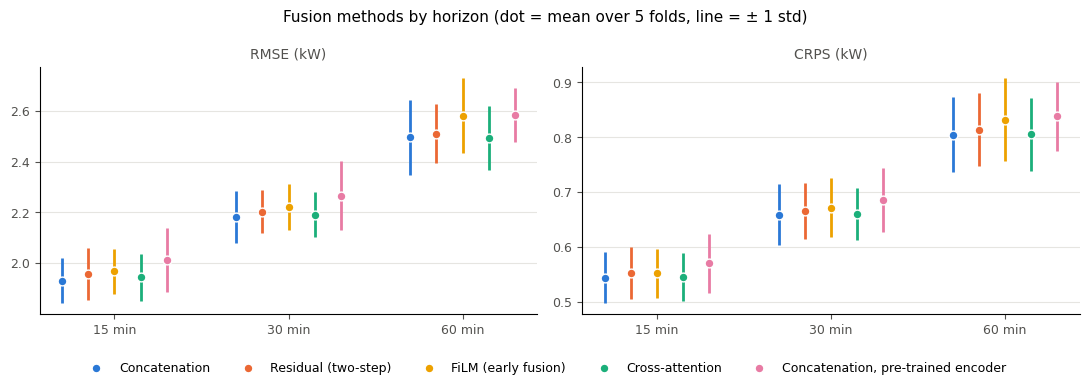

In [38]:
COLORS = dict(zip(METHODS, ["#2a78d6", "#eb6834", "#eda100", "#1baf7a", "#e87ba4"]))   # blue, orange, yellow, aqua, magenta
TEXT, GRID = "#52514e", "#e6e5e1"

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric in zip(axes, ["RMSE", "CRPS"]):
    s = results[results["weather"] == "all"].groupby(["model", "horizon"])[metric].agg(["mean", "std"])
    for k, m in enumerate(METHODS):
        x = np.arange(len(HORIZONS)) + (k - (len(METHODS) - 1) / 2) * 0.15
        mean, std = s.loc[m, "mean"].reindex(HORIZONS), s.loc[m, "std"].reindex(HORIZONS)
        ax.vlines(x, mean - std, mean + std, color=COLORS[m], linewidth=2)
        ax.scatter(x, mean, s=40, color=COLORS[m], edgecolor="white", linewidth=1, zorder=3, label=METHODS[m])
    ax.set_xticks(range(len(HORIZONS)), [f"{h} min" for h in HORIZONS])
    ax.set_title(f"{metric} (kW)", fontsize=10, color=TEXT)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXT, labelsize=9)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=len(METHODS), frameon=False, fontsize=9)
plt.suptitle("Fusion methods by horizon (dot = mean over 5 folds, line = ± 1 std)", fontsize=11)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

### 7.5 Where does the cross-attention model look?

Attention weights of the cross-attention model (15 minutes, fold 0) for one held-out sample of each weather bin: the sky image at t, then the 8 × 8 attention map of each of the 4 queries laid over it (brighter = more weight). Query 1 is computed from the history, queries 2–4 are learned. This is a qualitative check; `h` can be set to 30 or 60 for the longer horizons.

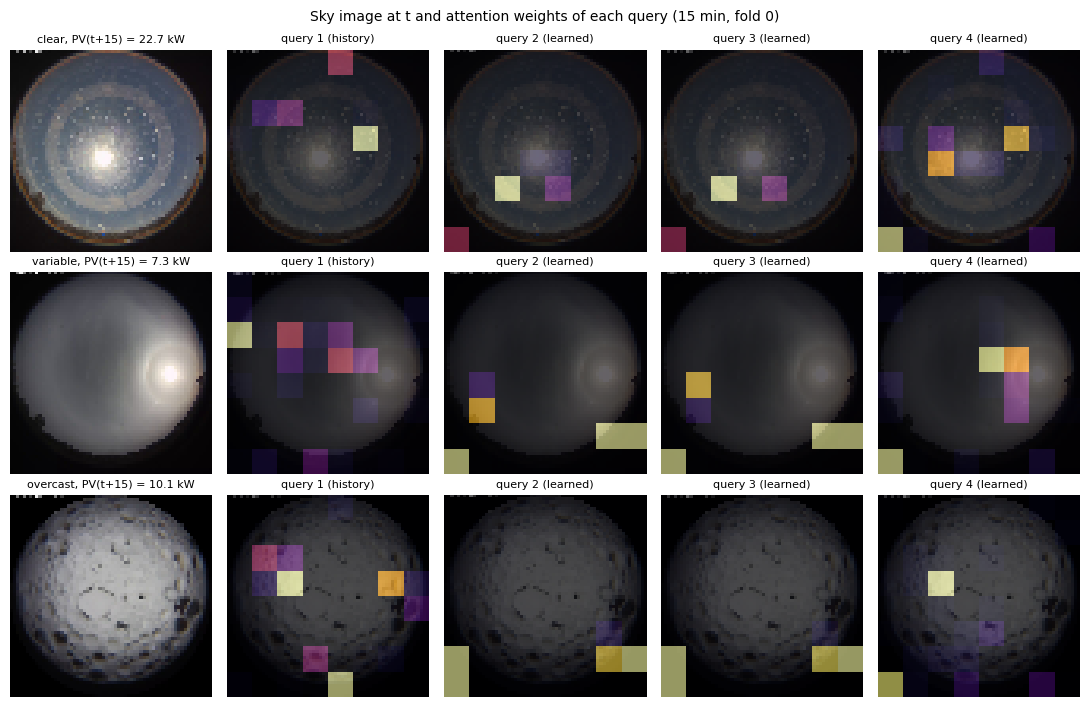

In [39]:
h, fold = 15, 0
checkpoint = torch.load(MODEL_DIR / f"fusion_xattn_h{h}_fold{fold}.pt", map_location=DEVICE, weights_only=False)
model = CrossAttentionFusion(**checkpoint["description"]["model_kwargs"]).to(DEVICE)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
model.keep_attention = True

data = DATA[h]
fit, _, evaluate = split_masks(data, fold)
get_batch, _, _, _ = prepare_fusion(data, fit)
rng = np.random.default_rng(SEED)
examples = np.array([rng.choice(np.flatnonzero(evaluate & (data.weather == w))) for w in WEATHER_BINS])
with torch.no_grad():
    forward_pass(model, get_batch(gpu(examples, torch.long)))
attention = model.last_attention.cpu().numpy()                     # (examples, queries, 8, 8)

n_queries = attention.shape[1]
fig, axes = plt.subplots(len(examples), n_queries + 1, figsize=(2.2 * (n_queries + 1), 2.4 * len(examples)))
for row, i in enumerate(examples):
    frame = IMAGES[data.image_rows[i, -1]].permute(1, 2, 0).cpu().numpy()
    axes[row, 0].imshow(frame)
    axes[row, 0].set_title(f"{data.weather[i]}, PV(t+{h}) = {data.pv_target[i]:.1f} kW", fontsize=8)
    for q in range(n_queries):
        axes[row, q + 1].imshow(frame)
        axes[row, q + 1].imshow(np.kron(attention[row, q], np.ones((8, 8))), cmap="inferno", alpha=0.6)
        axes[row, q + 1].set_title("query 1 (history)" if q == 0 else f"query {q + 1} (learned)", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle(f"Sky image at t and attention weights of each query ({h} min, fold {fold})", fontsize=10)
plt.tight_layout()
plt.show()